# Modélisation & Évaluation — Adult Income (UCI)

Ce notebook utilise les modules `ModelRegistry` (catalogue de classifieurs) et `ModelEvaluator` (cross-validation, évaluation test, comparaisons & graphes).

Pipeline : `DataLoader` → `PreprocessingPipeline` → modèles du `ModelRegistry` → `ModelEvaluator`.

In [1]:
# Recharge automatique des modules src/ modifiés sans restart du kernel
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Permet d'importer le package src/ depuis le dossier notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import matplotlib.pyplot as plt

from adult_income import (
    DataLoader,
    ModelEvaluator,
    ModelRegistry,
    PreprocessingPipeline,
)

print("Imports OK")

Imports OK


## 1 — Données & preprocessing

In [2]:
# --- Données : split train/test stratifié ---
loader = DataLoader(random_state=42)
X_train, X_test, y_train, y_test = loader.load_and_split()

# --- Preprocessing (one-hot + scaling, adapté aux modèles linéaires) ---
pp = PreprocessingPipeline(encoding="onehot", scaling=True)

# Encoder la cible (<=50K -> 0, >50K -> 1)
y_train_enc = pp.fit_transform_target(y_train)
y_test_enc = pp.transform_target(y_test)

print(f"Train : {X_train.shape[0]:,} obs | Test : {X_test.shape[0]:,} obs")

Train : 39,073 obs | Test : 9,769 obs


## 2 — Catalogue de modèles (`ModelRegistry`)

In [3]:
# Tous les modèles disponibles dans le catalogue
print("Modèles disponibles :")
for name in ModelRegistry.available():
    print(f"  - {name}")

Modèles disponibles :
  - logistic_regression
  - decision_tree
  - random_forest
  - gradient_boosting
  - adaboost
  - svm
  - knn
  - naive_bayes
  - xgboost
  - lightgbm
  - catboost


In [12]:
# Sous-ensemble à comparer (élargis la liste avec ModelRegistry.available())
model_names = ModelRegistry.available()  # ['logistic_regression', 'random_forest', 'gradient_boosting', 'xgboost', 'lightgbm']

models = ModelRegistry.get_subset(model_names)

# Pipelines complets : preprocessing + classifieur
pipelines = {name: pp.build_pipeline(est) for name, est in models.items()}
pipelines

{'logistic_regression': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   ['age', 'education-num',
                                                    'hours-per-week']),
                                                  ('num_asym',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('log1p',
                                                                  

## 3 — Cross-validation sur le train set (`ModelEvaluator`)

In [13]:
evaluator = ModelEvaluator(cv=5, random_state=42)
evaluator.cross_validate_all(pipelines, X_train, y_train_enc)

evaluator.cv_comparison_table()

  Evaluating logistic_regression... 

AUC=0.8982
  Evaluating decision_tree... AUC=0.7554
  Evaluating random_forest... AUC=0.9060
  Evaluating gradient_boosting... AUC=0.9219
  Evaluating adaboost... AUC=0.9063
  Evaluating svm... 

/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` param

AUC=0.8851
  Evaluating knn... AUC=0.8623
  Evaluating naive_bayes... AUC=0.8547
  Evaluating xgboost... AUC=0.9269
  Evaluating lightgbm... 

/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifi

AUC=0.9279
  Evaluating catboost... AUC=0.9287


,model,accuracy_mean,accuracy_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,roc_auc_mean,roc_auc_std
0,catboost,0.8733,0.0010,0.7114,0.0034,0.7819,0.0077,0.6527,0.0096,0.9287,0.0015
1,lightgbm,0.8733,0.0013,0.7124,0.0029,0.7797,0.0063,0.6558,0.0060,0.9279,0.0010
2,xgboost,0.8720,0.0024,0.7132,0.0040,0.7691,0.0115,0.6650,0.0078,0.9269,0.0015
3,gradient_boosting,0.8680,0.0020,0.6925,0.0067,0.7825,0.0064,0.6211,0.0117,0.9219,0.0017
4,adaboost,0.8534,0.0028,0.6543,0.0120,0.7506,0.0029,0.5803,0.0204,0.9063,0.0011
5,random_forest,0.8564,0.0020,0.6746,0.0057,0.7369,0.0060,0.6221,0.0096,0.9060,0.0014
6,logistic_regression,0.8431,0.0030,0.6372,0.0074,0.7132,0.0074,0.5759,0.0076,0.8982,0.0020
7,svm,0.8513,0.0024,0.6396,0.0074,0.7612,0.0051,0.5515,0.0090,0.8851,0.0031
8,knn,0.8353,0.0044,0.6380,0.0092,0.6729,0.0112,0.6066,0.0091,0.8623,0.0044
9,naive_bayes,0.7051,0.0022,0.5935,0.0031,0.4428,0.0021,0.8997,0.0091,0.8547,0.0054


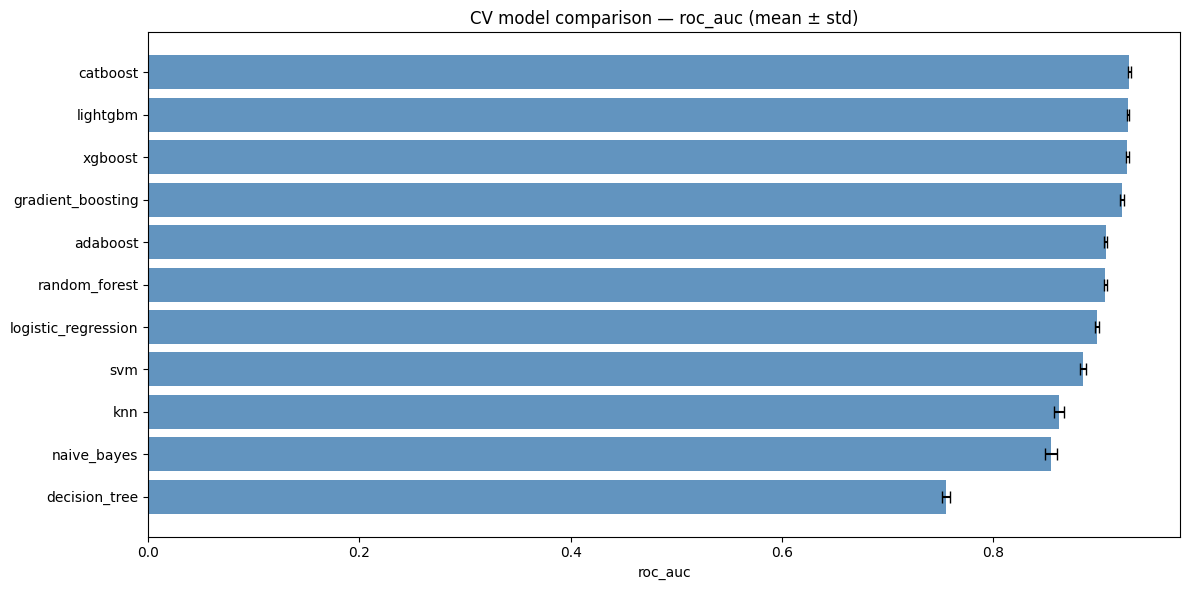

In [14]:
evaluator.plot_cv_comparison(metric="roc_auc")
plt.show()

## 4 — Évaluation finale sur le test set

In [15]:
for name, pipeline in pipelines.items():
    evaluator.evaluate_on_test(name, pipeline, X_train, y_train_enc, X_test, y_test_enc)

evaluator.test_comparison_table()

/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,accuracy,f1,precision,recall,roc_auc
0,catboost,0.8763,0.7209,0.7839,0.6672,0.9312
1,lightgbm,0.8742,0.7133,0.7845,0.6540,0.9299
2,xgboost,0.8767,0.7213,0.7854,0.6668,0.9294
3,gradient_boosting,0.8695,0.6965,0.7853,0.6257,0.9236
4,adaboost,0.8540,0.6535,0.7565,0.5753,0.9096
5,random_forest,0.8590,0.6837,0.7385,0.6364,0.9091
6,logistic_regression,0.8401,0.6304,0.7055,0.5697,0.8951
7,svm,0.8523,0.6418,0.7646,0.5530,0.8778
8,knn,0.8386,0.6462,0.6796,0.6159,0.8651
9,naive_bayes,0.7098,0.5964,0.4470,0.8961,0.8523


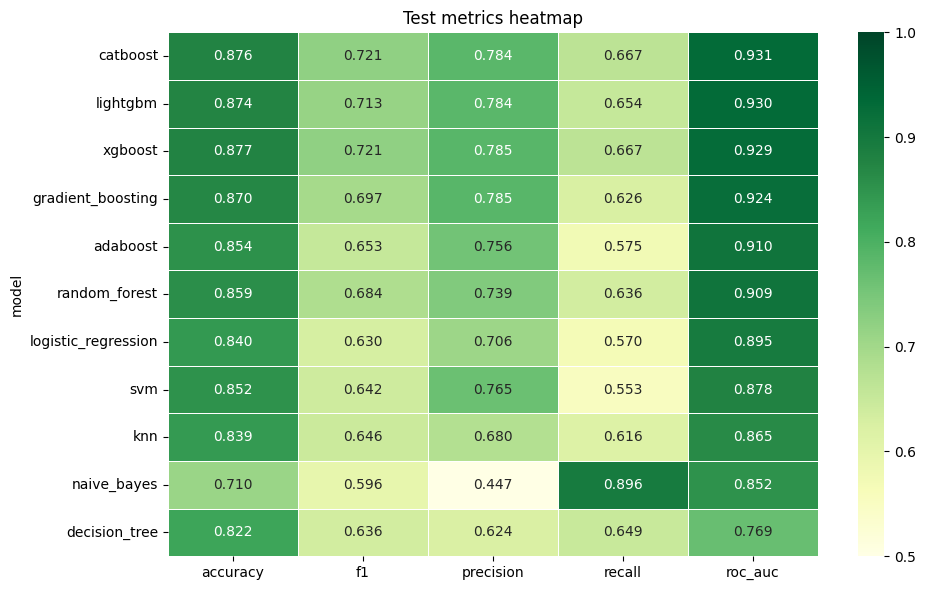

In [16]:
evaluator.plot_metric_heatmap()
plt.show()

/home/maxime/projet_ai28/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


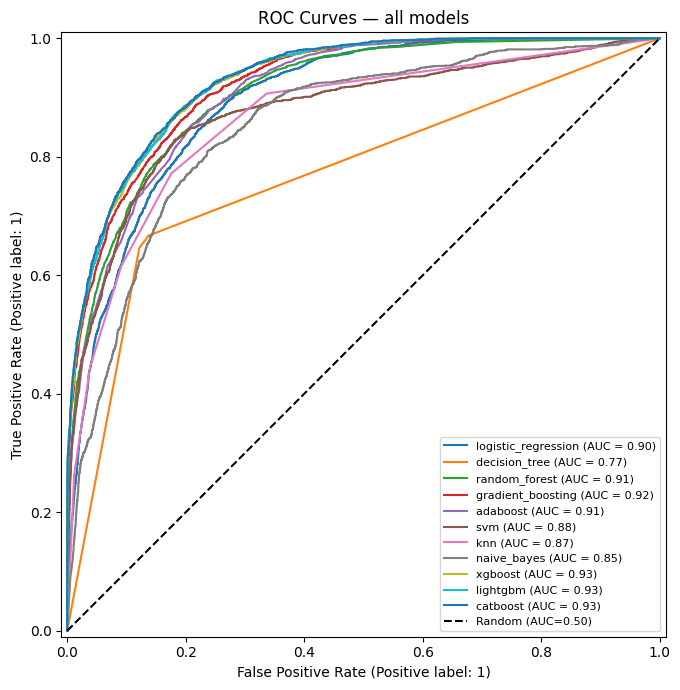

In [17]:
evaluator.plot_roc_curves(X_test, y_test_enc)
plt.show()

## 5 — Focus sur le meilleur modèle

In [18]:
best = evaluator.test_comparison_table().iloc[0]["model"]
print(f"Meilleur modèle (roc_auc test) : {best}")

evaluator.print_classification_report(best, pipelines[best], X_test, y_test_enc)

Meilleur modèle (roc_auc test) : catboost

catboost
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      7431
           1       0.78      0.67      0.72      2338

    accuracy                           0.88      9769
   macro avg       0.84      0.80      0.82      9769
weighted avg       0.87      0.88      0.87      9769



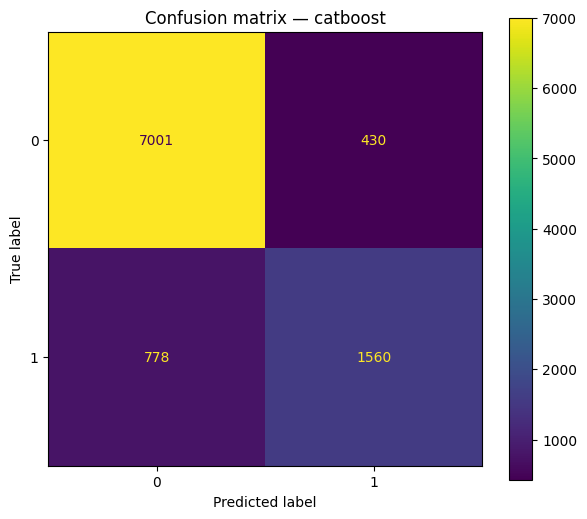

In [19]:
evaluator.plot_confusion_matrix(best, X_test, y_test_enc)
plt.show()